# Transfer learning: яблоки vs апельсины (ResNet-18, timm)

Классификация двух классов на **маленьком собственном датасете** (72 изображения в train, 59 в test) с предобученной на ImageNet моделью ResNet-18.
Сравниваются два приёма:

1. **Извлечение признаков (feature extraction):** все веса заморожены, обучается только новая «голова».
2. **Дообучение (fine-tuning):** размораживаются все веса, обучение с малым learning rate.

Данные в репозиторий не включены (фото из интернета). Структура: `train/apple`, `train/orange`, `test/apple`, `test/orange`.

## Создание датасета

В этом задании вам надо собрать собственный датасет из изображений. В нем должно быть минимум 30 изображений для каждого класса. Количество классов не менее 2. Тематику датасета вы выбираете самостоятельно.

Далее в этом разделе приведен пример кода, который помогает скачать изображения по запросу на гугл диск. Вы можете решить эту задачу другими удобными для вас способами, в том числе и вручную.

Если вы работаете с локальной средой, то код из примера придется модифицировать.

In [ ]:
import zipfile

zip_path = '/content/dataset.zip'
extract_path = '/content'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

In [ ]:
import os

def count_images(path):
    return len(os.listdir(path))

print("Train apples:", count_images('/content/train/apple'))
print("Train oranges:", count_images('/content/train/orange'))
print("Test apples:", count_images('/content/test/apple'))
print("Test oranges:", count_images('/content/test/orange'))

Train apples: 37
Train oranges: 37
Test apples: 30
Test oranges: 30


## Импортирование модулей

In [22]:
# по необходимости добавляйте свои модули

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision.transforms import v2
from torch.utils.data import Dataset, DataLoader
from torchvision.datasets import ImageFolder
import matplotlib.pyplot as plt

%matplotlib inline

In [ ]:
import random
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

In [23]:
# Использование GPU по желанию

if torch.cuda.is_available():
  device = torch.device('cuda')
  print('Работаем на GPU')
else:
  device = torch.device('cpu')
  print('Работаем на CPU')

# Не забывайте про .to(device)

Работаем на CPU


## Выбор модели из timm

В источниках к заданию, вы найдете список моделей, который выложен на github и [сравнение части моделей из timm](https://www.kaggle.com/code/jhoward/which-image-models-are-best). Вам необходимо остановить свой выбор на одной из них. В списке моделей на github есть ссылки на статьи о них, где можно найти информацию на каком датасете они были обучены.

Если вы работаете с фотографиями выбор можно остановить на одной из:
1. MobileNet,
1. VGG,
1. ResNet,
1. Xception.

По желанию можете попробовать несколько и сравнить.


In [24]:
# сначала требуется установить сам модуль timm
!pip install timm

In [25]:
import timm

In [26]:
# в качестве первого аргумента укажите имя выбранной модели
# и не забудьте указать, предобученный вариант (pretrained)
pretrained_model = timm.create_model(
    'resnet18',
    pretrained=True,
    num_classes=2
)

In [27]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pretrained_model = pretrained_model.to(device)

In [28]:
# Вывод архитектуры модели
print(pretrained_model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (act1): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (drop_block): Identity()
      (act1): ReLU(inplace=True)
      (aa): Identity()
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (act2): ReLU(inplace=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, m

В описании архитектуры модели в выводе предыдущей ячейки, найдите два новых модуля (Conv2d, ReLU вы уже знаете) и добавьте их описание.

**Ответ:**

1. `BatchNorm2d` нормализует активации по батчу (среднее 0, дисперсия 1) и добавляет обучаемые масштаб и сдвиг. Это стабилизирует и ускоряет обучение. Ведёт себя по-разному в `train()` и `eval()`, поэтому режимы нужно переключать.
1. `BasicBlock` (остаточный блок) складывает вход блока с результатом двух свёрток (skip-connection), поэтому градиент легче проходит через глубокую сеть. Ещё в сети есть `AdaptiveAvgPool2d`, который усредняет карты признаков до размера 1×1 независимо от размера входа.

**Почему решили выбрать именно эту модель?**

ResNet-18 небольшая и быстрая, при этом хорошо работает как извлекатель признаков. Датасет маленький, большая модель переобучилась бы сильнее. ImageNet, на котором она предобучена, уже содержит классы-апельсины и яблоки, поэтому признаки подходят.

## Создание Dataset и DataLoader

По аналогии с прошлыми заданиями нам требуется создать transforms, которые передаются в создаваемый Dataset и из датасета вы создаете DataLoaders.

Данных у нас немного, поэтому мы не будем выделять валидационную часть.

При создании transforms помните, что модель ожидает на вход тензор определенной размерности. В [описание моделей](https://paperswithcode.com/lib/timm), вы можете найти датасет, на котором обучалась модель и есть описание размера изображений.

Для работы вам пригодится:

- v2.ToImage()
- v2.Resize() или v2.RandomResizedCrop() - размер изображения после кадрирования, должен быть равен размеру ожидаемому на ходе предобученной модели.
- v2.RandomRotation()
- v2.RandomHorizontalFlip()
- v2.ToDtype()

[Описания в документации](https://pytorch.org/vision/stable/transforms.html#v2-api-reference-recommended)

In [29]:
from torchvision import transforms

train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

test_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])


In [30]:
train_dataset = ImageFolder(
    root='/content/train',
    transform=train_transforms
)

test_dataset = ImageFolder(
    root='/content/test',
    transform=test_transforms
)

In [31]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

In [32]:
print(train_dataset.classes)

['apple', 'orange']


**Почему выбрали именно такие преобразования (transforms) для данных?**

`Resize(224, 224)` и нормализация средними/стд ImageNet нужны, потому что ResNet предобучена именно на таком входе. Аугментации (поворот ±15°, отражение) применяются только к train: данных мало, и это снижает переобучение. На test только resize и нормализация, чтобы оценка была детерминированной.

## Прием извлечения признаков

Этот прием может использоваться как сам по себе, так и быть предварительным этапом для дообучения.

Он заключается в том, что мы заменяем полносвязную часть модели (head/голову) на свою с учетом размерностей выходных данных из сверточной части и количеством классов в текущей задаче. Перед обучением требуется "заморозить" параметры сверточных слоев.

**Почему требуется "заморозка" параметров?**

Ваш ответ:

Заморозка параметров необходима для того, чтобы сохранить уже обученные на датасете ImageNet признаки. Сверточные слои извлекают универсальные признаки изображений (границы, текстуры), поэтому их переобучение на небольшом датасете может привести к переобучению. Замораживание позволяет обучать только полносвязную часть модели под новую задачу.

У модели вы можете использовать метод .parameters(), он возвращает итерируемый объект с параметрами вашей модели. Вы можете их перебрать и отключить необходимость расчета градиентов.

In [33]:
# "Замораживаем" веса
for param in pretrained_model.parameters():
    param.requires_grad = False

# Заменяем "голову"
import torch.nn as nn

pretrained_model.fc = nn.Sequential(
    nn.Linear(pretrained_model.fc.in_features, 128),
    nn.ReLU(),
    nn.Linear(128, 2)
)

pretrained_model = pretrained_model.to(device)

In [34]:
loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    pretrained_model.fc.parameters(),
    lr=0.001
)

В этой работе также рассмотрим применение планировщика для изменения скорости обучения. Ранее у вас скорость обучения была константой, теперь же в процессе обучения каждые n эпох будем ее снижать.



In [35]:
from torch.optim import lr_scheduler

scheduler = lr_scheduler.StepLR(
    optimizer,
    step_size=5,   # каждые 5 эпох
    gamma=0.1      # уменьшаем lr
)


### Обучение и тестирование

Несколько эпох обучите модель в таком состоянии. Для обучения используйте уже знакомый вам цикл с эпохами и перебором dataloader, но к нему в цикл эпох требуется добавить шаг планировщика scheduler.step().

Не забывайте переключать режимы моделей (pretrained_model.train(), pretrained_model.eval()), так как теперь в них может быть пакетная нормализация и используйте контекст torch.no_grad() при проверке модели.

In [41]:
num_epochs = 10

for epoch in range(num_epochs):

    running_loss = 0.0
    correct = 0
    total = 0
    pretrained_model.train()

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = pretrained_model(images)
        loss = loss_fn(outputs, labels)

        loss.backward()
        optimizer.step()

        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
        running_loss += loss.item()

    print(f"Epoch {epoch+1}, Accuracy: {correct/total:.4f}, Loss: {running_loss/len(train_loader):.4f}")

    scheduler.step()

Epoch 1, Accuracy: 0.9722, Loss: 0.2876
Epoch 2, Accuracy: 0.9583, Loss: 0.3276
Epoch 3, Accuracy: 0.9583, Loss: 0.2563
Epoch 4, Accuracy: 0.9722, Loss: 0.2606
Epoch 5, Accuracy: 0.9722, Loss: 0.2675
Epoch 6, Accuracy: 0.9444, Loss: 0.2672
Epoch 7, Accuracy: 0.9722, Loss: 0.2588
Epoch 8, Accuracy: 0.9444, Loss: 0.3209
Epoch 9, Accuracy: 0.9444, Loss: 0.2889
Epoch 10, Accuracy: 0.9444, Loss: 0.2304


In [42]:
pretrained_model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)

        outputs = pretrained_model(images)
        _, preds = torch.max(outputs, 1)

        correct += (preds == labels).sum().item()
        total += labels.size(0)

print(f"Test Accuracy: {correct / total:.4f}")

Test Accuracy: 0.6949


## Прием дообучения

Чтобы дообучить модель, требуется разморозить параметры модели. Для упрощения можете разморозить все параметры модели, но более правильно будет разморозить параметры 1-2 последних слоев и оптимизировать их, и наиболее сложный вариант разморозить больше 2 слоев, но использовать сниженные скорости обучения для более ранних слоев модели - [TORCH.OPTIM](https://pytorch.org/docs/stable/optim.html#per-parameter-options).

In [43]:
for param in pretrained_model.parameters():
    param.requires_grad = True

In [44]:
# Новый набор объектов

optimizer = torch.optim.Adam(
    pretrained_model.parameters(),
    lr=1e-4
)

scheduler = lr_scheduler.StepLR(
    optimizer,
    step_size=5,
    gamma=0.1
)

In [45]:
# Новый цикл обучения

num_epochs = 10

for epoch in range(num_epochs):

    running_loss = 0.0
    correct = 0
    total = 0
    pretrained_model.train()

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = pretrained_model(images)
        loss = loss_fn(outputs, labels)

        loss.backward()
        optimizer.step()

        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
        running_loss += loss.item()

    print(f"Epoch {epoch+1}, Accuracy: {correct/total:.4f}, Loss: {running_loss/len(train_loader):.4f}")

    scheduler.step()

Epoch 1, Accuracy: 0.9583, Loss: 0.2559
Epoch 2, Accuracy: 0.9583, Loss: 0.2545
Epoch 3, Accuracy: 1.0000, Loss: 0.2320
Epoch 4, Accuracy: 1.0000, Loss: 0.1960
Epoch 5, Accuracy: 0.9861, Loss: 0.1749
Epoch 6, Accuracy: 0.9583, Loss: 0.2423
Epoch 7, Accuracy: 0.9861, Loss: 0.1679
Epoch 8, Accuracy: 1.0000, Loss: 0.1730
Epoch 9, Accuracy: 0.9861, Loss: 0.1533
Epoch 10, Accuracy: 0.9861, Loss: 0.1887


In [ ]:
# Оценка дообученной модели на тесте (feature extraction дала 69.5%)
pretrained_model.eval()
correct = total = 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        preds = pretrained_model(images).argmax(1)
        total += labels.size(0)
        correct += (preds == labels).sum().item()
print(f"Fine-tuning, точность на тесте: {correct / total:.4f} ({correct}/{total})")

Скачайте одно новое изображение, которое можно отнести к одному из ваших классов, и классифицируйте его с помощью полученной модели.

## Финал

Осталось попробовать модель на случайном изображении и ответить на вопросы.

In [57]:
from PIL import Image

def predict_image(path):

    image = Image.open(path).convert('RGB')

    img = test_transforms(image)
    img = img.unsqueeze(0).to(device)

    pretrained_model.eval()

    with torch.no_grad():
        outputs = pretrained_model(img)
        _, pred = torch.max(outputs, 1)

    classes = train_dataset.dataset.classes if hasattr(train_dataset, 'dataset') else train_dataset.classes


    print("Prediction:",classes[pred.item()])

    plt.imshow(image)
    plt.axis("off")
    plt.show()

Prediction: apple


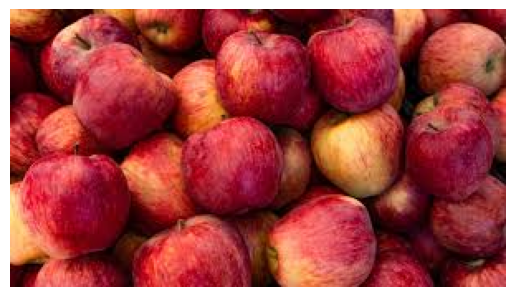

Prediction: orange


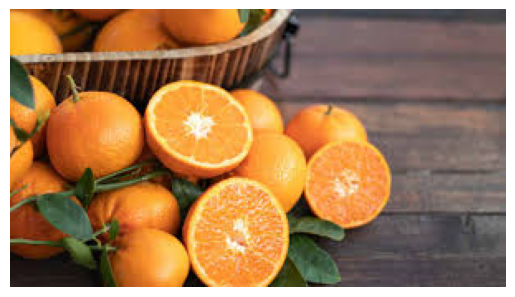

In [60]:
predict_image("apple.jpg")
predict_image("orange.jpg")

**Правильно ли модель классифицировала ваше изображение?**

Да: `apple.jpg` определено как apple, `orange.jpg` как orange. Но это два примера, а не оценка качества: на тесте модель ошибается заметно чаще (см. ниже).

**Какая итоговая точность работы вашей модели на тестовой выборке?**

Feature extraction: **69.5%** (41/59). При этом на train точность 94–100%, то есть сильное переобучение на 72 картинках.
Fine-tuning: <<ЗАПОЛНИТЬ числом из ячейки выше после запуска>>.

**Чем отличается прием извлечения признаков от дообучения?**

При извлечении признаков веса предобученной сети заморожены, обучается только новая голова, поэтому это быстро и устойчиво на малых данных. При дообучении размораживаются и сами свёрточные слои, модель подстраивается под задачу точнее, но риск переобучения выше, поэтому нужен малый learning rate.